# 04 · Skip connection: predicting the change instead of the level
**DNN Project 2 – Group 1** · Alphabet (GOOGL) daily stock data

Notebooks 02 and 03 established the diagnosis. The target is the raw price level, scaled with Min-Max fitted
on the training rows, and every test day lies above the highest training close. The hidden state passes
through `tanh`, bounded to [-1, 1], so the linear `Dense(1)` on top has a ceiling and the predictions fall
further below the actual price as it rises — a mean predicted change of −64 to −83 USD per day against an
actual +2.5.

This notebook tests the fix that follows directly from that diagnosis. One line changes:

```python
# notebook 02:  prediction = Dense(1)(h)
# here:         prediction = last_close_in_window + Dense(1)(h)
```

The network no longer has to produce the price. It produces the **one-day change**, which is added to a value
it already has in its input. The target is still the next day's closing price, exactly as requirement §4.6
specifies, and the data, the split, the scaler and the training procedure are untouched.

> **This is a supplementary experiment, not a replacement.** The architecture required by §6.1 is
> `Input → SimpleRNN(64, tanh) → Dropout(0.2) → Dense(1)`, and notebook 02 keeps it unchanged. The three
> models here are an addition for the discussion of §8.6.

| Section | What it does |
|---|---|
| 1 | Setup and load the sequences written by notebook 01 |
| 2 | The skip connection: architecture, and a check that the output really is `last + Δ` |
| 3 | Train the three architectures with the same 5 seeds as notebook 02 |
| 4 | Results against notebook 02 and against persistence |
| 5 | Did it create directional skill? |
| 6 | Where the improvement comes from |
| 7 | Discussion |

**Reads** `../data/processed/`, `../results/02_model_training/runs_per_seed.csv` ·
**Writes** `../results/04_skip/`, `../models/skip_*.keras`

## 1. Setup

In [1]:
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from scipy import stats
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras import Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import GRU, LSTM, Add, Dense, Dropout, Input, SimpleRNN
from tensorflow.keras.optimizers import Adam

tf.get_logger().setLevel("ERROR")

PROC_DIR = "../data/processed"                       # written by notebook 01
NB02_DIR = "../results/02_model_training"            # written by notebook 02
RESULTS_DIR = "../results/04_skip"
MODELS_DIR = "../models"
os.makedirs(RESULTS_DIR, exist_ok=True)

WINDOW = 30
MODELS = ["SimpleRNN", "GRU", "LSTM"]
SEEDS = [42, 43, 44, 45, 46]     # the same seeds as notebook 02, so the comparison is paired
BATCH_SIZE = 32
MAX_EPOCHS = 100
PATIENCE = 10


def save(name):
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, name), dpi=150)
    plt.show()

### 1.1 Load the sequences
Identical to notebook 02: same file, same split, same scaler. Nothing about the data changes in this
experiment, which is what makes the comparison fair.

In [2]:
d = np.load(os.path.join(PROC_DIR, f"sequences_w{WINDOW}.npz"))
data = {k: (d[f"X_{k}"], d[f"y_{k}"]) for k in ("train", "val", "test")}
(X_train, y_train), (X_val, y_val), (X_test, y_test) = data["train"], data["val"], data["test"]
dates_test = pd.to_datetime(d["dates_test"])
CLOSE_IDX = list(d["features"]).index("Close")
target_scaler = joblib.load(os.path.join(PROC_DIR, "target_scaler.joblib"))


def to_usd(a):
    return target_scaler.inverse_transform(np.asarray(a).reshape(-1, 1)).ravel()


def metrics_usd(y_true, y_pred):
    yt, yp = to_usd(y_true), to_usd(y_pred)
    mse = mean_squared_error(yt, yp)
    return {"MAE": mean_absolute_error(yt, yp), "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(yt, yp)}


persistence = {k: X[:, -1, CLOSE_IDX] for k, (X, _) in data.items()}
baseline = {k: metrics_usd(data[k][1], persistence[k]) for k in data}

for k, (X, y) in data.items():
    print(f"{k:<5} X={X.shape}  persistence RMSE = {baseline[k]['RMSE']:7.2f} USD")

train X=(3071, 30, 1)  persistence RMSE =    6.39 USD
val   X=(665, 30, 1)  persistence RMSE =   16.19 USD
test  X=(665, 30, 1)  persistence RMSE =   35.57 USD


## 2. The skip connection
The functional API is needed here, because a `Sequential` model cannot route the input around the recurrent
layer. Written out, the model computes

$$\hat{y}_t = c_{t-1} + f_\theta(x_t) \qquad c_{t-1} = \text{last close in the window}$$

where $f_\theta$ is exactly the stack used in notebook 02. Two consequences:

- **The ceiling disappears.** `Dense(1)` only has to output a change of a few USD. The large number comes
  from the input, which is not passed through `tanh`.
- **The floor becomes persistence.** If training fails and $f_\theta \to 0$, the model degenerates into
  "tomorrow = today" and scores the baseline's 35.57 USD. In notebook 02 the floor was 103–205 USD.

Note that this is mathematically the same as training on the target $y_t - c_{t-1}$ and adding $c_{t-1}$
back afterwards, since $\text{MSE}(y, c + \Delta) = \text{MSE}(y - c, \Delta)$. It is written as an
architecture rather than as a new target so that the target stays the next day's close, as §4.6 requires.

In [3]:
def build_skip(kind, units=64, lr=1e-3, input_shape=None):
    """Same stack as notebook 02, but the output is added to the last close of the input window."""
    layer = {"SimpleRNN": SimpleRNN, "GRU": GRU, "LSTM": LSTM}[kind]
    inp = Input(shape=input_shape or X_train.shape[1:])
    h = layer(units, activation="tanh")(inp)
    h = Dropout(0.2)(h)
    delta = Dense(1, name="delta")(h)           # the one-day change, in scaled units
    last = inp[:, -1, CLOSE_IDX:CLOSE_IDX + 1]  # (batch, 1): today's close, straight from the input
    out = Add()([last, delta])
    model = Model(inp, out, name=f"skip_{kind}")
    model.compile(optimizer=Adam(learning_rate=lr), loss="mse")
    return model


build_skip("SimpleRNN").summary()

Model: "skip_SimpleRNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 30, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn          │ (None, 64)        │      4,224 │ input_layer[0][0] │
│ (SimpleRNN)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ simple_rnn[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 1)         │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ delta (Dense)       │ (None, 1)         │         65 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 1)         │          0 │ get_item[0][0],   │
│                     │                   │            │ delta[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,289 (16.75 KB)

 Trainable params: 4,289 (16.75 KB)

 Non-trainable params: 0 (0.00 B)

### 2.1 Check that the output really is `last + Δ`
An untrained model is enough: if the wiring is right, the prediction minus the last close must equal the
`Dense(1)` output exactly, and the parameter count must match notebook 02 (the skip connection adds none).
The `Dense` layer is given the explicit name `delta` in `build_skip`, because Keras otherwise appends a
counter (`dense_1`, `dense_2`, …) that changes every time a model is built in the same session.

In [4]:
probe = build_skip("SimpleRNN")
delta_only = Model(probe.input, probe.get_layer("delta").output)   # named in build_skip, so no auto-suffix

pred = probe.predict(X_test[:200], verbose=0).ravel()
delta = delta_only.predict(X_test[:200], verbose=0).ravel()
last = X_test[:200, -1, CLOSE_IDX]

assert np.allclose(pred, last + delta, atol=1e-6)      # the skip connection is wired as intended
assert probe.count_params() == 4289                     # same as the SimpleRNN of notebook 02
print("wiring verified: prediction == last close + Dense(1) output")
print(f"parameters: {probe.count_params():,} (identical to notebook 02 — a skip connection has no weights)")

wiring verified: prediction == last close + Dense(1) output
parameters: 4,289 (identical to notebook 02 — a skip connection has no weights)


## 3. Training
The same procedure as notebook 02 so that nothing but the architecture differs: Adam at 1e-3, MSE loss,
batch 32, at most 100 epochs, early stopping on validation loss with patience 10 and the best weights
restored, and the same five seeds.

In [5]:
def train(model, epochs=MAX_EPOCHS):
    cb = [EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)]
    return model.fit(*data["train"], validation_data=data["val"], epochs=epochs,
                     batch_size=BATCH_SIZE, callbacks=cb, verbose=0)


runs, best = [], {}
for kind in MODELS:
    for seed in SEEDS:
        tf.keras.utils.set_random_seed(seed)
        model = build_skip(kind)
        hist = train(model)
        pred = {k: model.predict(X, verbose=0).ravel() for k, (X, _) in data.items()}
        run = {"model": kind, "seed": seed, "epochs run": len(hist.history["loss"]),
               "best epoch": int(np.argmin(hist.history["val_loss"])) + 1,
               "val_loss": min(hist.history["val_loss"]), "pred": pred}
        runs.append(run)
        if kind not in best or run["val_loss"] < best[kind]["val_loss"]:
            best[kind] = {**run, "keras": model, "history": hist.history}
    model_path = os.path.join(MODELS_DIR, f"skip_{kind.lower()}.keras")
    best[kind]["keras"].save(model_path)
    print(f"{kind:<10} 5 seeds done, best on validation: seed {best[kind]['seed']}, "
          f"saved to {os.path.basename(model_path)}")

SimpleRNN  5 seeds done, best on validation: seed 43, saved to skip_simplernn.keras


GRU        5 seeds done, best on validation: seed 44, saved to skip_gru.keras


LSTM       5 seeds done, best on validation: seed 45, saved to skip_lstm.keras


## 4. Results
`skip_results` holds one row per run, in the same shape as `runs_per_seed.csv` from notebook 02, so the two
can be put side by side.

In [6]:
skip_results = pd.DataFrame([{
    "model": r["model"], "seed": r["seed"], "epochs run": r["epochs run"], "best epoch": r["best epoch"],
    "train RMSE": metrics_usd(y_train, r["pred"]["train"])["RMSE"],
    "val RMSE": metrics_usd(y_val, r["pred"]["val"])["RMSE"],
    **metrics_usd(y_test, r["pred"]["test"]),
} for r in runs])
skip_results.to_csv(os.path.join(RESULTS_DIR, "runs_per_seed.csv"), index=False)
skip_results.round(3)

,model,seed,epochs run,best epoch,train RMSE,val RMSE,MAE,MSE,RMSE,R2
0,SimpleRNN,42,42,32,6.400,16.258,25.120,1316.101,36.278,0.997
1,SimpleRNN,43,54,44,6.384,16.145,27.199,1433.364,37.860,0.996
2,SimpleRNN,44,22,12,6.493,16.460,26.223,1407.672,37.519,0.996
3,SimpleRNN,45,25,15,6.460,16.374,32.353,2000.650,44.729,0.995
4,SimpleRNN,46,26,16,6.687,16.657,25.558,1293.495,35.965,0.997
5,GRU,42,15,5,6.709,16.156,25.049,1275.586,35.715,0.997
6,GRU,43,13,3,6.433,16.660,34.871,2142.988,46.292,0.994
7,GRU,44,30,20,6.698,16.136,29.181,1609.694,40.121,0.996
8,GRU,45,11,1,6.391,16.178,24.887,1264.807,35.564,0.997
9,GRU,46,40,30,6.626,16.144,26.418,1373.307,37.058,0.996


### 4.1 Against notebook 02 and the baseline
Test RMSE, mean ± standard deviation over the same five seeds.

In [7]:
plain = pd.read_csv(os.path.join(NB02_DIR, "runs_per_seed.csv"))
cmp = pd.DataFrame({
    "notebook 02 (plain)": plain.groupby("model", sort=False)["RMSE"].mean(),
    "02 std": plain.groupby("model", sort=False)["RMSE"].std(),
    "notebook 04 (skip)": skip_results.groupby("model", sort=False)["RMSE"].mean(),
    "04 std": skip_results.groupby("model", sort=False)["RMSE"].std(),
}).loc[MODELS]
cmp["improvement x"] = cmp["notebook 02 (plain)"] / cmp["notebook 04 (skip)"]
cmp["vs persistence"] = cmp["notebook 04 (skip)"] / baseline["test"]["RMSE"]
cmp.loc["Persistence"] = [baseline["test"]["RMSE"], 0.0, baseline["test"]["RMSE"], 0.0, 1.0, 1.0]
cmp.round(2)

,notebook 02 (plain),02 std,notebook 04 (skip),04 std,improvement x,vs persistence
model,,,,,,
SimpleRNN,205.34,75.75,38.47,3.59,5.34,1.08
GRU,158.48,31.79,38.95,4.49,4.07,1.10
LSTM,102.97,45.28,37.51,2.48,2.75,1.05
Persistence,35.57,0.00,35.57,0.00,1.00,1.00


In [8]:
METRICS = ["MAE", "MSE", "RMSE", "R2"]
stats_tab = skip_results.groupby("model", sort=False)[METRICS].agg(["mean", "std"])
stats_tab.loc["Persistence"] = [v for m in METRICS for v in (baseline["test"][m], 0.0)]
stats_tab = stats_tab.loc[["Persistence", *MODELS]]
stats_tab.columns = [f"{m} {s}" for m, s in stats_tab.columns]
stats_tab.to_csv(os.path.join(RESULTS_DIR, "test_metrics.csv"))
stats_tab.round(4)

,MAE mean,MAE std,MSE mean,MSE std,RMSE mean,RMSE std,R2 mean,R2 std
model,,,,,,,,
Persistence,24.7910,0.0000,1264.9070,0.0000,35.5655,0.0000,0.9967,0.0000
SimpleRNN,27.2906,2.9365,1490.2563,291.3776,38.4701,3.5891,0.9961,0.0008
GRU,28.0812,4.1677,1533.2765,367.9871,38.9502,4.4941,0.9960,0.0010
LSTM,26.4560,2.1308,1411.7127,188.4941,37.5074,2.4768,0.9963,0.0005


In [9]:
rmse = (skip_results.groupby("model", sort=False)[["train RMSE", "val RMSE", "RMSE"]].mean()
        .rename(columns={"RMSE": "test RMSE"}))
rmse.loc["Persistence"] = [baseline[k]["RMSE"] for k in ("train", "val", "test")]
rmse = rmse.loc[["Persistence", *MODELS]]
for k in ("val", "test"):
    rmse[f"{k} / persistence"] = rmse[f"{k} RMSE"] / baseline[k]["RMSE"]
rmse.round(2)

,train RMSE,val RMSE,test RMSE,val / persistence,test / persistence
model,,,,,
Persistence,6.39,16.19,35.57,1.00,1.00
SimpleRNN,6.48,16.38,38.47,1.01,1.08
GRU,6.57,16.25,38.95,1.00,1.10
LSTM,6.40,16.19,37.51,1.00,1.05


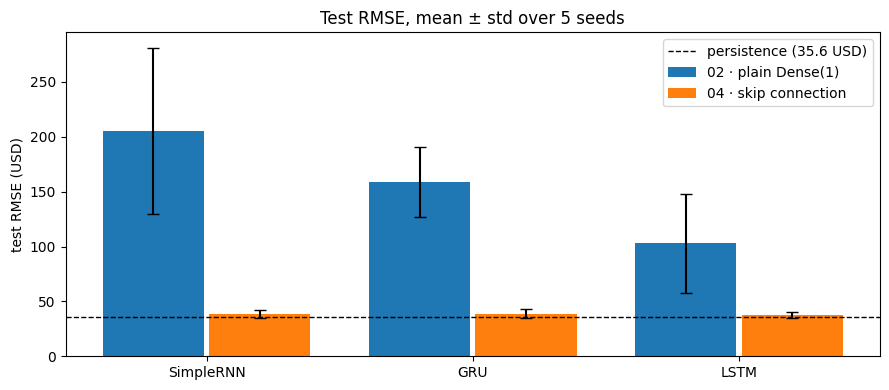

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(MODELS))
ax.bar(x - 0.2, cmp.loc[MODELS, "notebook 02 (plain)"], 0.38,
       yerr=cmp.loc[MODELS, "02 std"], capsize=4, label="02 · plain Dense(1)")
ax.bar(x + 0.2, cmp.loc[MODELS, "notebook 04 (skip)"], 0.38,
       yerr=cmp.loc[MODELS, "04 std"], capsize=4, label="04 · skip connection")
ax.axhline(baseline["test"]["RMSE"], color="black", linestyle="--", linewidth=1,
           label=f"persistence ({baseline['test']['RMSE']:.1f} USD)")
ax.set_xticks(x, MODELS)
ax.set_ylabel("test RMSE (USD)")
ax.set_title("Test RMSE, mean ± std over 5 seeds")
ax.legend()
save("rmse_comparison.png")

## 5. Did it create directional skill?
Notebook 03 found none: directional accuracy at chance on both splits and no significant correlation
between the predicted and the actual daily change. The skip connection removes the bias, so the question is
whether anything appears once the bias is gone. The measurements are the same as in notebook 03, applied to
the seed selected on validation.

In [11]:
rows = []
for split in ("val", "test"):
    X, y = data[split]
    last = to_usd(X[:, -1, CLOSE_IDX])
    act = to_usd(y) - last
    up_rate = (act > 0).mean()
    for kind in MODELS:
        prd = to_usd(best[kind]["pred"][split]) - last
        hit = (act > 0) == (prd > 0)
        sp = stats.spearmanr(prd, act)
        rows.append({
            "split": split, "model": kind,
            "DA %": 100 * hit.mean(),
            "predicted up %": 100 * (prd > 0).mean(),
            "majority %": 100 * max(up_rate, 1 - up_rate),
            "mean pred change": prd.mean(),
            "mean actual change": act.mean(),
            "Spearman r": sp.statistic,
            "p": sp.pvalue,
        })
direction = pd.DataFrame(rows)
direction.to_csv(os.path.join(RESULTS_DIR, "direction_metrics.csv"), index=False)
direction.round(4)

,split,model,DA %,predicted up %,majority %,mean pred change,mean actual change,Spearman r,p
0,val,SimpleRNN,55.9398,67.9699,53.0827,0.5280,0.5192,0.1074,0.0056
1,val,GRU,51.1278,49.0226,53.0827,-0.0800,0.5192,0.0885,0.0225
2,val,LSTM,49.0226,18.3459,53.0827,-0.6843,0.5192,0.0979,0.0115
3,test,SimpleRNN,44.3609,10.5263,55.9398,-8.1659,2.5213,-0.0152,0.6954
4,test,GRU,42.7068,4.0602,55.9398,-12.2850,2.5213,-0.0061,0.8761
5,test,LSTM,44.0602,1.5038,55.9398,-12.2407,2.5213,0.0205,0.5978


## 6. Where the improvement comes from
Two views of the same thing: the predictions over the test period, and the error over time next to
notebook 02's models.

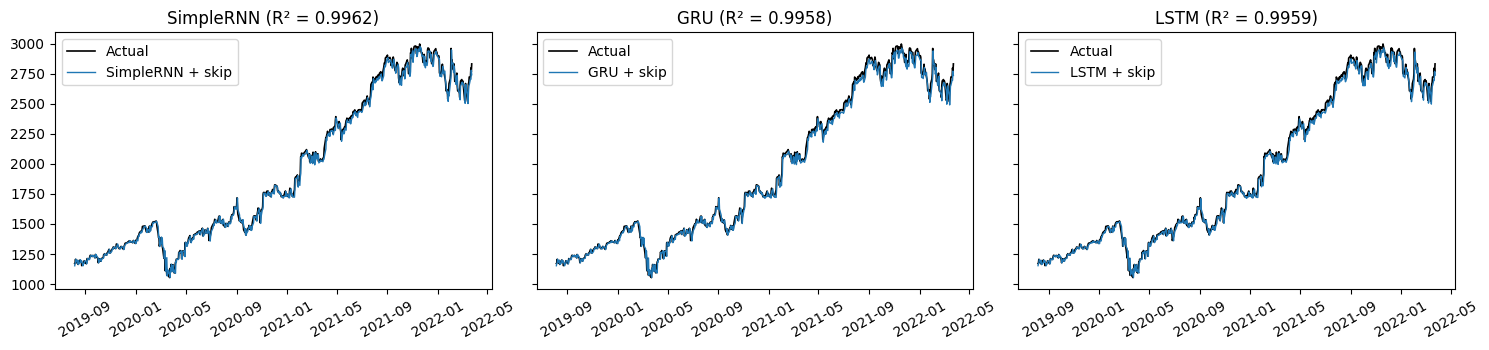

In [12]:
actual = to_usd(y_test)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, kind in zip(axes, MODELS):
    p = to_usd(best[kind]["pred"]["test"])
    ax.plot(dates_test, actual, color="black", linewidth=1.2, label="Actual")
    ax.plot(dates_test, p, linewidth=1, label=f"{kind} + skip")
    ax.set_title(f"{kind} (R² = {metrics_usd(y_test, best[kind]['pred']['test'])['R2']:.4f})")
    ax.tick_params(axis="x", rotation=30)
    ax.legend()
save("test_predictions_skip.png")

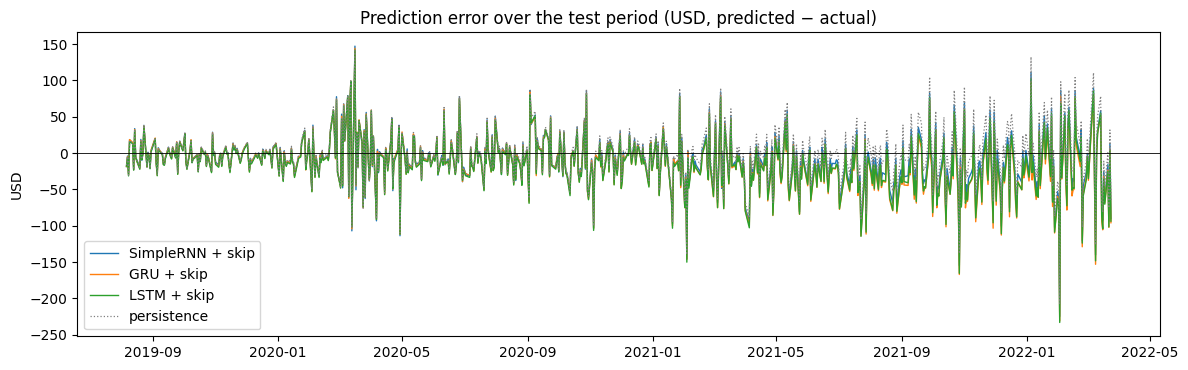

In [13]:
fig, ax = plt.subplots(figsize=(12, 3.8))
for kind in MODELS:
    ax.plot(dates_test, to_usd(best[kind]["pred"]["test"]) - actual, linewidth=1, label=f"{kind} + skip")
ax.plot(dates_test, to_usd(persistence["test"]) - actual, color="grey", linewidth=0.9,
        linestyle=":", label="persistence")
ax.axhline(0, color="black", linewidth=0.6)
ax.set_title("Prediction error over the test period (USD, predicted − actual)")
ax.set_ylabel("USD")
ax.legend()
save("test_errors_skip.png")

## 7. Discussion

**The diagnosis is confirmed.** One line changed, nothing else, and the gap to the baseline essentially
closed:

| | Notebook 02 | Notebook 04 | Improvement |
|---|---|---|---|
| SimpleRNN | 205.34 ± 75.75 | **38.47 ± 3.59** | 5.3× |
| GRU | 158.48 ± 31.79 | **38.95 ± 4.49** | 4.1× |
| LSTM | 102.97 ± 45.28 | **37.51 ± 2.48** | 2.7× |
| Persistence | 35.57 | 35.57 | — |

Against the baseline the ratio falls from **2.90–5.77×** to **1.05–1.10×**. Since the data, the split, the
scaler, the seeds and the training procedure are all unchanged, the cause of the original gap can only be
the thing that was removed: the network having to produce the price level through a bounded `tanh` state.
Capacity, architecture and feature choice were never the bottleneck, which is what notebooks 02 and 03
argued from indirect evidence and what this measures directly.

**Seed variance collapsed too.** The standard deviation over the five seeds drops from 75.75, 31.79 and
45.28 USD to 3.59, 4.49 and 2.48. In notebook 02 a single run mostly measured its seed; here the three
architectures are no longer distinguishable from one another, and all of them sit just above persistence.

**On the training and validation splits they now simply tie the baseline.** Training RMSE 6.40–6.57 against
persistence 6.39, validation 16.19–16.38 against 16.19. LSTM matches the baseline to two decimals on both.
The underfitting reported in notebook 02 section 10 — every model worse than persistence even on the data it
was trained on — is gone.

**They still do not beat persistence.** 1.05–1.10× means the learned change contributes slightly more noise
than signal. The clearest case is GRU with seed 45: early stopping restored the weights of **epoch 1** and
the run scored 35.564 USD against the baseline's 35.566 — the network found that predicting "no change" was
as good as anything else it could reach, and stopped. Training also converges far sooner than in notebook 02
(11–54 epochs against 22–100), and nothing came close to the 100-epoch cap that LSTM kept hitting there.

**No directional skill appeared on the test set, as predicted.** Directional accuracy is 42.7–44.4 %, still
below a coin flip, because a smaller downward bias remains: a mean predicted change of −8 to −12 USD per day
against an actual +2.5. That is a seven-fold reduction from the −64 to −83 of notebook 03, but it is not
zero, so the models still answer "down" too often. Spearman correlations on test are −0.015, −0.006 and
0.021 with p-values of 0.70, 0.88 and 0.60 — nothing.

**The validation result in section 5 looks different, and should not be trusted.** There the correlations
are 0.088–0.107 with p-values of 0.006–0.023, which would be significant taken at face value. They should
not be: **the validation set chose these models**. Early stopping picks the epoch with the lowest validation
loss, and section 3 picks the seed with the lowest validation loss. A metric computed on the data used for
selection is optimistically biased by construction. The test set is the only clean estimate here, and it
shows nothing. This is the same trap the project avoided elsewhere by never selecting on test, and it is
worth stating explicitly rather than quietly reporting the higher number.

**What this means for the project as a whole.** Notebook 03 separated two problems. This notebook settles
both of them:

| Problem | Prediction | Outcome |
|---|---|---|
| Target leaves the training range | The skip connection should close most of the RMSE gap | **Confirmed** — 2.7–5.3× better, now within 10 % of the baseline |
| The series is close to a random walk | Directional skill should stay absent | **Confirmed** — test accuracy still at or below chance, correlations ≈ 0 |

So the poor numbers in notebook 02 came from how the problem was posed, not from the models — and fixing
that recovers the baseline but does not beat it, because beating it would require information that 30 days
of closing prices do not contain. Requirement §4.5 and §4.6 prescribe the framing that causes the first
problem, so notebook 02 remains the answer to the assignment; this notebook explains what that framing cost
and shows the number it cost.